<a href="https://colab.research.google.com/github/cikicali369-glitch/DSB-MTN-Git-Starter/blob/main/lab_regression_sacramento_Ali_Cikic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/cikicali369-glitch/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/lab-regression-sacramento-YOURNAME-HERE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://github.com/cikicali369-glitch/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Simple Linear Regression with Sacramento Real Estate Data

---

In this lab you will hone your exploratory data analysis (EDA) skills and practice constructing linear regressions on a data set of Sacramento real estate sales.  The data set contains information on qualities of the property, location of the property, and time of sale.

Ali Cikic

### 1. Read in the Sacramento housing data set.

The file is stored in the `data` subfolder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# iskljucujemo upozorenja da output bude citljiviji
import warnings
warnings.filterwarnings('ignore')

# URL
url = 'https://raw.githubusercontent.com/cikicali369-glitch/DSB-Unit-03/main/labs/01%20-%20Regression-Sacramento/data/sacramento_real_estate_transactions.csv'

# zip citamo kao tekst (string), da ne izgubimo nule na pocetku
df = pd.read_csv(url, dtype={'zip': str})
df.head()

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768


### 2. Conduct exploratory data analysis on this data set.

If you discover any issues with the data, fix them to the best of your ability. Report any notable findings.

_**Note:** Zip codes often have leading zeros — e.g., 02215 = Boston, MA — which will often get knocked off automatically by many software programs like Python or Excel._

In [2]:
# 1. Pregled osnovnih informacija i tipova podataka
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     985 non-null    object 
 1   city       985 non-null    object 
 2   zip        985 non-null    object 
 3   state      985 non-null    object 
 4   beds       985 non-null    int64  
 5   baths      985 non-null    int64  
 6   sq__ft     985 non-null    int64  
 7   type       985 non-null    object 
 8   sale_date  985 non-null    object 
 9   price      985 non-null    int64  
 10  latitude   985 non-null    float64
 11  longitude  985 non-null    float64
dtypes: float64(2), int64(4), object(6)
memory usage: 92.5+ KB


In [3]:
# 2. Provjera da li imamo nedostajućih (null) vrijednosti
df.isnull().sum()

,0
street,0
city,0
zip,0
state,0
beds,0
baths,0
sq__ft,0
type,0
sale_date,0
price,0


In [4]:
# 3. Osnovna statistika za numericke kolone
df.describe()

,beds,baths,sq__ft,price,latitude,longitude
count,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000
mean,2.911675,1.776650,1312.918782,233715.951269,38.445121,-121.193371
std,1.307932,0.895371,856.123224,139088.818896,5.103637,5.100670
min,0.000000,0.000000,-984.000000,-210944.000000,-121.503471,-121.551704
25%,2.000000,1.000000,950.000000,145000.000000,38.482704,-121.446119
50%,3.000000,2.000000,1304.000000,213750.000000,38.625932,-121.375799
75%,4.000000,2.000000,1718.000000,300000.000000,38.695589,-121.294893
max,8.000000,5.000000,5822.000000,884790.000000,39.020808,38.668433


`describe()` shows some strange values: `sq__ft`, `beds` and `baths` have a minimum of **0**, and `price` and `sq__ft` even have **negative** minimums. A house can't have 0 square feet or a negative price, so let's check these rows.

In [5]:
# Koliko kuca ima 0 kvadrata, 0 soba ili 0 kupatila
print('sq__ft = 0:', (df['sq__ft'] == 0).sum())
print('beds = 0:', (df['beds'] == 0).sum())
print('baths = 0:', (df['baths'] == 0).sum())
print('price <= 0:', (df['price'] <= 0).sum())

sq__ft = 0: 171
beds = 0: 108
baths = 0: 108
price <= 0: 1


In [6]:
# Red sa negativnom cijenom
df[df['price'] < 0]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
703,1900 DANBROOK DR,SACRAMENTO,95835,AC,1,1,-984,Condo,Fri May 16 00:00:00 EDT 2008,-210944,-121.503471,38.668433


In [7]:
# Provjera kategorijskih kolona
print(df['state'].value_counts())
print()
print(df['type'].value_counts())

state
CA    984
AC      1
Name: count, dtype: int64

type
Residential     917
Condo            54
Multi-Family     13
Unkown            1
Name: count, dtype: int64


**Problems I found in the data:**

- **171 houses have `sq__ft = 0`.** A house can't have 0 square feet, so these are missing values that were filled with 0. Most of these houses also have `beds = 0` and `baths = 0` (108 of them).
- **One row is completely broken (row 703):** price is **-210,944**, `sq__ft` is -984, `state` is "AC" instead of "CA", and latitude and longitude are switched. It looks like the values were entered with a minus sign / in the wrong columns.
- `type` has the value **"Unkown"** (with a typo) for one house, so we don't know what type it is.
- `zip` was read as a number, so I read it again as a string (text), because zip codes are labels, not numbers.

**What I will do:** remove the broken row and all houses with `sq__ft = 0`. I could fill the zeros with the mean, but that would put fake values in our most important variable, and we still have enough data left (~800 rows).

In [8]:
# Ciscenje podataka
print('Prije ciscenja:', df.shape)

# 1) izbacujemo pokvaren red (negativna cijena, state = 'AC')
df = df[df['price'] > 0]

# 2) izbacujemo kuce sa 0 kvadrata (to su nedostajuce vrijednosti, ne prave nule)
df = df[df['sq__ft'] > 0]

# 3) izbacujemo kucu od 5822 kvadrata koja je prodana za samo $2,000 (sigurno greska u unosu)
df = df[df['price'] > 2000]

print('Poslije ciscenja:', df.shape)

# Provjera da vise nema nula i negativnih vrijednosti
df[['price', 'sq__ft', 'beds', 'baths']].describe()

Prije ciscenja: (985, 12)
Poslije ciscenja: (812, 12)


,price,sq__ft,beds,baths
count,812.000000,812.000000,812.000000,812.00000
mean,229751.267241,1586.683498,3.247537,1.95936
std,119704.946884,647.477210,0.849490,0.66594
min,30000.000000,484.000000,1.000000,1.00000
25%,148750.000000,1144.000000,3.000000,2.00000
50%,207986.500000,1418.500000,3.000000,2.00000
75%,285000.000000,1851.000000,4.000000,2.00000
max,884790.000000,4400.000000,8.000000,5.00000


In [9]:
# Provjera: da li su sada sve kategorije ok
print(df['state'].value_counts())
print()
print(df['type'].value_counts())

state
CA    812
Name: count, dtype: int64

type
Residential     758
Condo            41
Multi-Family     13
Name: count, dtype: int64


After cleaning we have **812 rows**. There are no more zeros or negative values, `state` is only "CA", and the "Unkown" type disappeared (that house also had `sq__ft = 0`, so it was removed).

When I made the scatter plots below the first time, I also saw one house with 5822 square feet that was sold for only **$2,000**. That is not a realistic price, so I removed it as well (step 3 in the cleaning code).

When you've finished cleaning or have made a good deal of progress cleaning, it's always a good idea to save your work. Use the pandas `to_csv` method to export your cleaned dataset.

```python
# example -- your dataframe name may be different
dataframe.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)

```

In [10]:
# Snimamo ociscen dataset
import os
os.makedirs('./datasets', exist_ok=True)

df.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)
print("Uspješno sačuvano u './datasets/sacramento_cleaned_dataframe.csv'!")

Uspješno sačuvano u './datasets/sacramento_cleaned_dataframe.csv'!


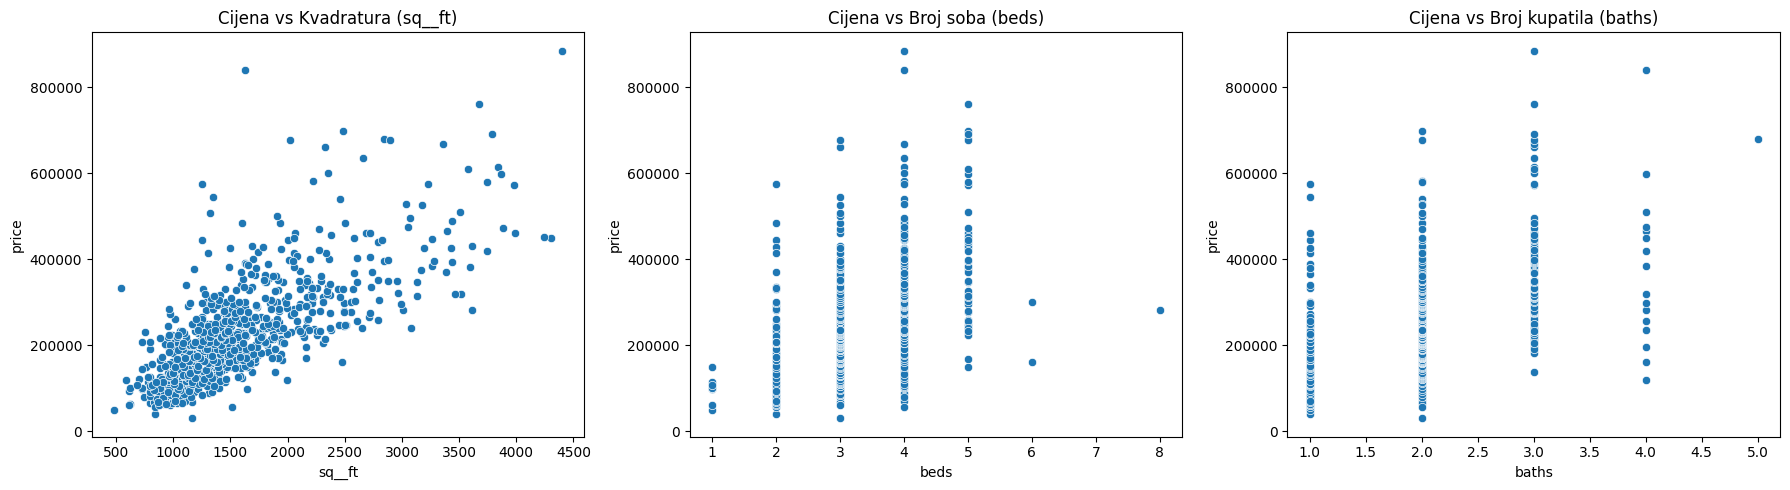

In [11]:
# Crtamo grafove za potencijalne prediktore cijene (na ociscenim podacima)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='sq__ft', y='price', ax=axes[0])
axes[0].set_title('Cijena vs Kvadratura (sq__ft)')

sns.scatterplot(data=df, x='beds', y='price', ax=axes[1])
axes[1].set_title('Cijena vs Broj soba (beds)')

sns.scatterplot(data=df, x='baths', y='price', ax=axes[2])
axes[2].set_title('Cijena vs Broj kupatila (baths)')

plt.tight_layout()
plt.show()

# Single Linear Regression Model (SLR)

### 3. Our goal will be to predict price. List variables that you think qualify as predictors of price in an SLR model.

For each of the variables you believe should be considered, generate a plot showing the relationship between the independent and dependent variables.

I think these variables could be good predictors of price:

- `sq__ft` (size of the house) - bigger houses should cost more.
- `beds` (number of bedrooms)
- `baths` (number of bathrooms)

The scatter plots above show their relationship with price, and below I also checked the correlation of each one with price.

In [12]:
# Korelacija svake varijable sa cijenom
df[['price', 'sq__ft', 'beds', 'baths']].corr()['price'].sort_values(ascending=False)

,price
price,1.000000
sq__ft,0.728862
baths,0.513391
beds,0.443719


### 4. Which variable would be the best predictor of Y in an SLR model? Why?

`sq__ft` is the best predictor of price for an SLR model.

- It has the **highest correlation** with price (about **0.73**), while `baths` has ~0.51 and `beds` ~0.44.
- In the scatter plot we can see a clear positive, roughly linear trend: when the size goes up, the price goes up too.
- `beds` and `baths` only have a few possible values (1, 2, 3...), so in the plots the points are in vertical lines and for the same number of rooms the price is very different.

### 5. Using `scikit-learn` create a SLR and return the intercept and slope coefficients that minimize SSE.

#### SSE (Sum of Squared Errors)

SSE is just the total of all the squared prediction mistakes.

1. For each data point, figure out how far off your prediction was (actual minus predicted).
2. Square that number (to make negatives positive and punish big errors more).
3. Add them all up.

**Why it matters:** You were asked to find the slope and intercept that **minimize SSE**. That's literally what linear regression does — it searches for the line that makes this total as small as possible.

**Related terms:**
- **MSE** = SSE ÷ n (average of the squared errors)
- **RMSE** = √MSE (puts it back in original units)

So: **SSE → MSE → RMSE** is just the same number, adjusted differently for interpretation purposes.


-----

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```



In [13]:
from sklearn.linear_model import LinearRegression

# 1. Postavljamo naš prediktor (X) i ciljnu varijablu (y)
X = df[['sq__ft']]
y = df['price']

# 2. Inicijalizujemo i treniramo model linearne regresije
model = LinearRegression()
model.fit(X, y)

# 3. Ispisujemo dobijene koeficijente
print("Intercept (β0):", model.intercept_)
print("Slope (β1):", model.coef_[0])

Intercept (β0): 15943.749961489259
Slope (β1): 134.7512075418882


### 5 [bonus]. Write a function that will take in two lists, `x` and `y`, and return the intercept and slope coefficients that minimize SSE.

`y` is the target variable, and `x` is the predictor variable.

**Don't use `scikit-learn` for this**. Instead, use `numpy` and `scipy`.

The slope and intercept of simple linear regression can be calculated by using certain summary statistics. In particular, we'll need to know:

- $\bar{x}$, the mean of `x`
- $\bar{y}$, the mean of `y`
- $s_{x}$, the standard deviation of `x`
- $s_{y}$, the standard deviation of `y`
- $r_{xy}$, the correlation of `x` and `y`

Given these summary statistics, the **coefficient on `X`** (or the slope) can be given by $\beta_{1} = r_{xy} * \frac{s_{y}}{s_{x}}$. The **intercept of the model** can be given by $\beta_{0} = \bar{y} - \beta_{1}\bar{x}$.

Your function should take in `x` and `y`, then use the above summary statistics to calculate the slope and intercept.

- **Test your function on price and the variable you determined was the best predictor in Problem 4.**
- **Report the slope and intercept.**

In [14]:
import numpy as np

def calculate_slope_intercept(x, y):
    # 1. Srednje vrijednosti (means)
    x_bar = np.mean(x)
    y_bar = np.mean(y)

    # 2. Standardne devijacije (sa ddof=1 za uzorak)
    s_x = np.std(x, ddof=1)
    s_y = np.std(y, ddof=1)

    # 3. Korelacija između x i y
    r_xy = np.corrcoef(x, y)[0, 1]

    # 4. Izračunavanje nagiba (slope / beta_1)
    beta_1 = r_xy * (s_y / s_x)

    # 5. Izračunavanje presjeka (intercept / beta_0)
    beta_0 = y_bar - (beta_1 * x_bar)

    return beta_0, beta_1

# Testiramo funkciju na kvadraturi (sq__ft) i cijeni (price)
intercept, slope = calculate_slope_intercept(df['sq__ft'], df['price'])

print("Izračunati Intercept (β0):", intercept)
print("Izračunati Slope (β1):", slope)

Izračunati Intercept (β0): 15943.749961489404
Izračunati Slope (β1): 134.7512075418881


### 6. Interpret the intercept and the slope.

In your own words, write here what is the meaning of each one of those values
and how can they be helpful for you when predicting prices or interpreting the
predictions of your model.

- **Intercept (β0 ≈ 15,944):** this is the predicted price of a house with 0 square feet. In real life this doesn't make sense (there are no houses with 0 sq ft), so it is just the starting point of the line and we shouldn't interpret it literally.
- **Slope (β1 ≈ 134.75):** for every 1 extra square foot, the predicted price goes up by about **$134.75** on average. For example, a house that is 100 sq ft bigger is predicted to cost about $13,475 more.
- This is helpful because with just these two numbers we can quickly estimate the price of a house if we know its size, and we can also see how much size matters for the price.

### 7. Give an example of how this model could be used for prediction and how it could be used for inference.

**Be sure to make it clear which example is associated with prediction and which is associated with inference.**

**Prediction example:** someone wants to sell a house of 2,000 sq ft in Sacramento and wants to know what price to expect. We put X = 2000 into the model:

Price = 15,944 + 134.75 × 2,000 ≈ **$285,446**

So the model predicts a price of about $285,000.

**Inference example:** a real estate agent doesn't want to predict a specific house, but wants to *understand* the market: "How much does size affect price in Sacramento?" We look at the slope and say: on average, every additional 100 sq ft is associated with about **$13,475** higher price. Here we use the model to understand the relationship, not to predict one price.

### 8: [Bonus] Using the model you came up with in Part 5, calculate and plot the residuals.

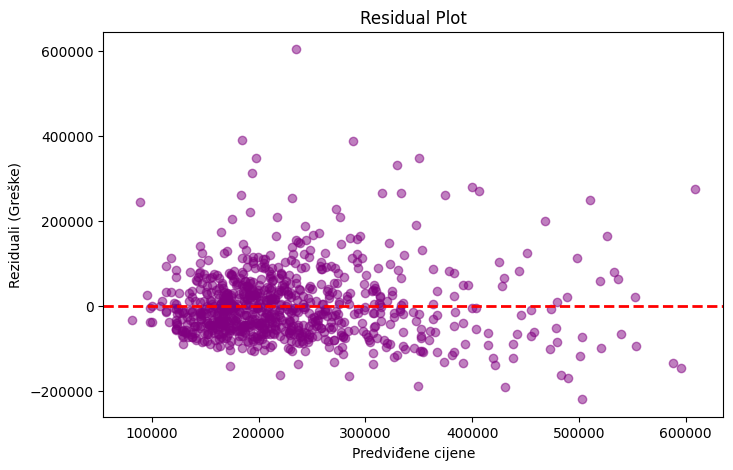

In [15]:
# Izračunavamo predikcije i reziduale
y_pred = model.predict(X)
residuals = y - y_pred

# Crtamo rezidualni plot
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predviđene cijene')
plt.ylabel('Reziduali (Greške)')
plt.title('Residual Plot')
plt.show()

**What I see in the residual plot:**

- Most residuals are around 0, so on average the model is not too high or too low.
- But the points spread out more as the predicted price gets bigger (the errors for expensive houses are bigger than for cheap houses). This is a sign of **heteroscedasticity**.
- There are also some big positive residuals (houses that sold for much more than the model predicted), which means the model doesn't capture everything that makes a house expensive (for example location).

---

## Reminder about categorical variables and dummy variables

It is important to be cautious with categorical variables, which represent distict groups or categories, when building a regression. If put in a regression "as-is," categorical variables represented as integers will be treated like *continuous* variables.

That is to say, instead of group "3" having a different effect on the estimation than group "1" it will estimate literally 3 times more than group 1.

For example, if occupation category "1" represents "analyst" and occupation category "3" represents "barista", and our target variable is salary, if we leave this as a column of integers then barista will always have `beta*3` the effect of analyst.

This will almost certainly force the beta coefficient to be something strange and incorrect. Instead, we can re-represent the categories as multiple "dummy coded" columns.



#### A Word of Caution When Creating Dummies

Let's touch on precautions we should take when dummy coding.

**If you convert a qualitative variable to dummy variables, you want to turn a variable with N categories into N-1 variables.**

> **Scenario 1:** Suppose we're working with the variable "sex" or "gender" with values "M" and "F".

You should include in your model only one variable for "sex = F" which takes on 1 if sex is female and 0 if sex is not female! Rather than saying "a one unit change in X," the coefficient associated with "sex = F" is interpreted as the average change in Y when sex = F relative to when sex = M.

| Female | Male |
|-------|------|
| 0 | 1 |
| 1 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 0 |
_As we can see a 1 in the female column indicates a 0 in the male column. And so, we have two columns stating the same information in different ways._

> Scenario 2: Suppose we're modeling revenue at a bar for each of the days of the week. We have a column with strings identifying which day of the week this observation occured in.

We might include six of the days as their own variables: "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday". **But not all 7 days.**  

|Monday | Tuesday | Wednesday | Thursday | Friday | Saturday |
|-------|---------|-----------|----------|--------|----------|
| 1     | 0       |0          |      0   |0       | 0        |
| 0     | 1       |0          |      0   |0       | 0        |
| 0     | 0       |1          |      0   |0       | 0        |
| 0     | 0       |0          |      1   |0       | 0        |
| 0     | 0       |0          |      0   |1       | 0        |
| 0     | 0       |0          |      0   |0       | 1        |
| 0     | 0       |0          |      0   |0       | 0        |

_As humans we can infer from the last row that if its is not Monday, Tuesday, Wednesday, Thursday, Friday or Saturday, it must be Sunday. Models work the same way._

The coefficient for Monday is then interpreted as the average change in revenue when "day = Monday" relative to "day = Sunday." The coefficient for Tuesday is interpreted as the average change in revenue when "day = Tuesday" relative to "day = Sunday" and so on.

The category you leave out, which the other columns are *relative to*, is often referred to as the **reference category**.

### 9. Use the `pd.get_dummies` function to convert the `type` column into dummy-coded variables.

In [16]:
# Korak 9: Kreiramo dummy varijable za tip nekretnine
# dtype=int da dobijemo 0/1 umjesto True/False
df = pd.get_dummies(df, columns=['type'], drop_first=True, dtype=int)

print("Dummy varijable su uspješno kreirane!")

Dummy varijable su uspješno kreirane!


### 10. Check the dummy columns you've created. Do they all make sense?

Use `.head()` on the new dataframe you've created. Depending on how you cleaned the data earlier in this notebook, there may be a dummy column that needs to be removed. Check that all the columns you've created make sense, and if any of the columns seem to be errors, drop them. If there don't appear to be any errors, then move on to the next step!

In [17]:
# Korak 10: Provjeravamo novouređeni dataframe sa dummy kolonama
df.head()

,street,city,zip,state,beds,baths,sq__ft,sale_date,price,latitude,longitude,type_Multi-Family,type_Residential
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879,0,1
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028,0,1
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839,0,1
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146,0,1
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768,0,1


The dummy columns are `type_Multi-Family` and `type_Residential`. They make sense:

- `Condo` is the **reference category** (it was dropped because of `drop_first=True`), so a 0 in both columns means the house is a Condo.
- In the original data there was also a type "Unkown", which would have created a wrong column `type_Unkown`. That house was already removed during cleaning (it had `sq__ft = 0`), so we don't have this column and there is nothing to drop.
- I used `dtype=int` so the columns are 0/1 instead of True/False.

# Multivariate Linear Regression Model (MLR)

### 11. Build what you think may be the best MLR model predicting `price`.

Choose at least three variables, and build a model that uses them to predict price. At least one of the variables you choose should be a dummy-coded variable. (This can be one we created before or a new one.)

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```

In [18]:
from sklearn.linear_model import LinearRegression

# Definiramo naše tri varijable i ciljnu cijenu
features = ['sq__ft', 'beds', 'type_Residential']
X_mlr = df[features]
y = df['price']

# Treniramo multivarijatni model
mlr_model = LinearRegression()
mlr_model.fit(X_mlr, y)

print("Intercept:", mlr_model.intercept_)
for f, c in zip(features, mlr_model.coef_):
    print(f"Koeficijent za {f}: {c}")

Intercept: 26344.535224773135
Koeficijent za sq__ft: 156.63086849212894
Koeficijent za beds: -25716.904313934727
Koeficijent za type_Residential: 41135.31439229756


### 12. Plot the true price vs the predicted price to evaluate your MLR visually.

You can use matplotlib or seaborn, the choice is yours !

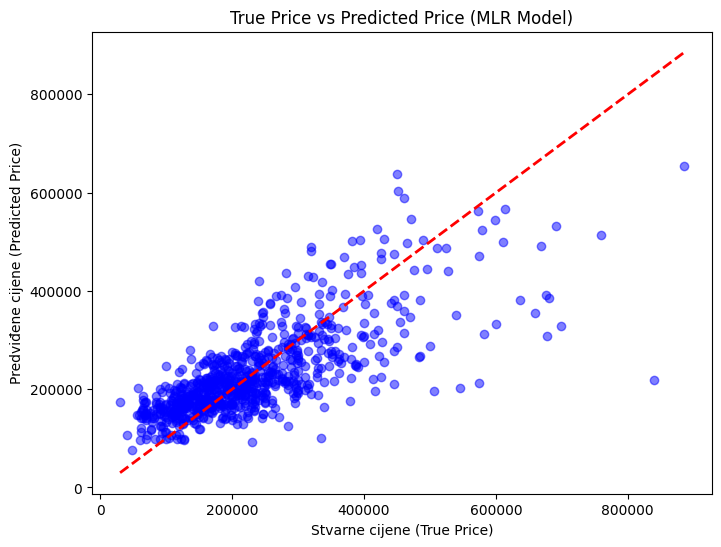

In [19]:
# 1. Izračunavamo predviđene cijene za MLR model
y_pred_mlr = mlr_model.predict(X_mlr)

# 2. Crtamo scatter plot: Stvarne vs Predviđene cijene
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred_mlr, alpha=0.5, color='blue')

# Dodajemo idealnu liniju (gdje su stvarna i predviđena cijena iste)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)

plt.xlabel('Stvarne cijene (True Price)')
plt.ylabel('Predviđene cijene (Predicted Price)')
plt.title('True Price vs Predicted Price (MLR Model)')
plt.show()

The points follow the red line (perfect prediction) reasonably well for cheaper houses (up to around $300,000). For more expensive houses the points are more spread out and most of them are **under** the red line, which means the model **underestimates the price of expensive houses**.

### 13. List the five assumptions for an MLR model.

Indicate which ones are the same as the assumptions for an SLR model.

1. **Linearity:** the relationship between the predictors and the target (price) is linear. (Same as SLR)
2. **Independence:** the errors (residuals) are independent of each other. (Same as SLR)
3. **Normality:** the errors are normally distributed. (Same as SLR)
4. **Equal variance (homoscedasticity):** the errors have the same variance for all predicted values. (Same as SLR)
5. **No multicollinearity:** the predictors are not strongly correlated with each other. (Only for MLR, because in SLR we only have one predictor)

### 14. Pick at least two assumptions and explain whether or not you believe them to be met for your model, and explain why.

1. **Linearity - mostly met.** In the scatter plot of `sq__ft` vs price we can see a roughly linear trend, and in the residual plot the points are around 0 without a clear curve.
2. **Equal variance (homoscedasticity) - not met.** In the residual plot the errors get bigger when the predicted price gets bigger (the points spread out to the right). So the model is less precise for expensive houses.
3. **No multicollinearity - partly violated.** `sq__ft` and `beds` are connected (bigger houses have more bedrooms). We can see this in the model: the coefficient for `beds` is **negative**, which doesn't make sense alone. It happens because `sq__ft` already explains the size of the house. Also the statsmodels summary warns about a large condition number, which can mean multicollinearity.

### 15. [Bonus - optional] Generate a table showing the point estimates, standard errors, t-scores, p-values, and 95% confidence intervals for the model you built.

**Write a few sentences interpreting some of the output.**

> **Hint:** scikit-learn does not have this functionality built in, but statsmodels does in the `summary` method.  To fit the statsmodels model use something like the following.  There is one big caveat here, however!  `statsmodels.OLS` does _not_ add an intercept to your model, so you will need to do this explicitly by adding a column filled with the number 1 to your X matrix

```python
import statsmodels.api as sm

# The Default here is Linear Regression (ordinary least squares regression OLS)
model = sm.OLS(y,X).fit()
```

In [20]:
import statsmodels.api as sm

# 1. Dodajemo intercept (konstantnu kolonu sa jedinicama) u našu X matricu
X_mlr_sm = sm.add_constant(X_mlr)

# 2. Kreiramo i fitujemo OLS model
ols_model = sm.OLS(y, X_mlr_sm).fit()

# 3. Prikazujemo tabelu sa rezultatima
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     330.4
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          5.97e-140
Time:                        20:00:29   Log-Likelihood:                -10321.
No. Observations:                 812   AIC:                         2.065e+04
Df Residuals:                     808   BIC:                         2.067e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             2.634e+04    1.4e+04      1.885      0.060   -1090.827    5.38e+04
sq__ft             156.6309      6.250     25.059      0.000     144.362     168.900
beds             -2.572e+04   4835.811     -5.318      0.000   -3.52e+04   -1.62e+04
type_Residential  4.114e+04   1.16e+04      3.541      0.000    1.83e+04    6.39e+04
==============================================================================
Omnibus:                      320.422   Durbin-Watson:                   1.161
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1926.205
Skew:                           1.677   Prob(JB):                         0.00
Kurtosis:                       9.759   Cond. No.                     9.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

- **sq__ft (coef ≈ 156.6, p < 0.001):** holding beds and type the same, every extra square foot adds about $157 to the price. The 95% confidence interval is about 144 to 169, so we are quite sure the effect is positive.
- **beds (coef ≈ -25,717, p < 0.001):** if two houses have the same size, the one with one more bedroom is predicted to be about $25,700 cheaper. This sounds strange, but it means that for the same size, more bedrooms = smaller rooms. It is probably also caused by multicollinearity with `sq__ft`.
- **type_Residential (coef ≈ 41,135, p < 0.001):** compared to a Condo (reference category), a residential house costs about $41,000 more with the same size and number of bedrooms.
- **const (p ≈ 0.06):** the intercept is not statistically significant (p > 0.05), but that is not important because a house with 0 sq ft doesn't exist.
- All three predictors have p-values below 0.05, so they are all statistically significant.

### 16. Metrics, metrics, everywhere...

Calculate and interpret at least three regression metrics. How well does your model perform?

## Metric Comparison Table

| Metric | What It Tells You | Punishes Big Mistakes? | Adjusts for Extra Inputs? | Examples of When to Use It |
|---|---|---|---|---|
| **R²** | What percent of the output's variation did the model explain? (0% to 100%) | Indirectly | ❌ No | • Pitching model quality in a presentation: "My model explains 73% of the price variation."<br>• Comparing two models on the same dataset.<br>• Quick sanity check: if R² is near zero, your inputs aren't helping. |
| **Adjusted R²** | Like R², but penalizes you for throwing in too many inputs | Indirectly | ✅ Yes | • You add/remove variables and want to know if performance truly improved.<br>• Deciding whether a new feature is worth keeping in production.<br>• Anytime you're comparing models with different numbers of predictors. |
| **MSE** | Average squared error. Lower is better. | ✅ Strongly (squared!) | ❌ No | • The loss function that regression algorithms optimize internally.<br>• Math-heavy contexts (calculus, derivation).<br>• Rarely reported to stakeholders — too abstract. |
| **RMSE** | On average, how far off are predictions (in original units)? | ✅ Strongly | ❌ No | • "Predictions are off by ~$45,000 on average."<br>• Reporting to non-technical audiences who want dollar amounts.<br>• When large outliers matter and you want to catch them. |
| **MAE** | On average, how far off are predictions (in original units)? | ❌ Mildly (linear) | ❌ No | • When outliers are noisy measurements you don't want to overweight.<br>• Plain-language explanations: "Typical error is about $40,000."<br>• When you want a robust, easy-to-grasp error measure. |

---

## Which Metrics to Report?

**Quick analogy:** If you're reporting to your professor, think of it like grading on multiple axes:
- **R²** answers: "How much of the puzzle did you solve?"
- **RMSE/MAE** answer: "By how many points, on average, were your answers wrong?"
- **Adjusted R²** answers: "Did you actually improve, or just throw more pages at the problem?"

In [21]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Izračunavamo metrike za naš MLR model
r2 = r2_score(y, y_pred_mlr)
rmse = np.sqrt(mean_squared_error(y, y_pred_mlr))
mae = mean_absolute_error(y, y_pred_mlr)

print(f"R-squared (R²): {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R-squared (R²): 0.5509
RMSE: 80171.2306
MAE: 57594.1297


- **R² ≈ 0.55:** the model explains about **55%** of the variation in house prices. The other 45% comes from things that are not in the model (location, age of the house, lot size...).
- **RMSE ≈ $80,171:** on average our predictions are about $80,000 away from the real price. RMSE punishes big errors more, and we have some very expensive houses with big errors.
- **MAE ≈ $57,594:** the typical error is about $57,600. It is smaller than RMSE because MAE doesn't punish big errors as much.

**How good is it?** The average price is about $230,000, so an error of ~$58,000-$80,000 is quite big. The model is OK for a rough estimate, but not precise enough to set an exact price for a house.

### 16. [Bonus - Optional] Regression Metrics

Implement a function called `r2_adj()` that will calculate $R^2_{adj}$ for a model.

In [22]:
def r2_adj(y_true, y_pred, X):
    # 1. Izračunavamo standardni R²
    r2 = r2_score(y_true, y_pred)

    # 2. Broj uzoraka (n) i broj prediktora (p)
    n = len(y_true)
    p = X.shape[1]

    # 3. Formula za Adjusted R²
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

    return adj_r2

# Testiramo našu funkciju na našem MLR modelu
calculated_adj_r2 = r2_adj(y, y_pred_mlr, X_mlr)

print(f"Adjusted R²: {calculated_adj_r2:.4f}")

Adjusted R²: 0.5492


### 18. Model Iteration

Adjust your model by adding or removing a variable. Then calculate the same regression metrics as you used in question 17. Has your model performance increased or decreased?

In [23]:
# Dodajemo novu varijablu 'baths' u našu listu prediktora
features_v2 = ['sq__ft', 'beds', 'baths', 'type_Residential']
X_mlr_v2 = df[features_v2]

# Treniramo novi model
mlr_model_v2 = LinearRegression()
mlr_model_v2.fit(X_mlr_v2, y)

# Izračunavamo nove metrike
y_pred_v2 = mlr_model_v2.predict(X_mlr_v2)
r2_v2 = r2_score(y, y_pred_v2)
rmse_v2 = np.sqrt(mean_squared_error(y, y_pred_v2))
mae_v2 = mean_absolute_error(y, y_pred_v2)
adj_r2_v2 = r2_adj(y, y_pred_v2, X_mlr_v2)

print(f"Stari model -> R²: {r2:.4f} | Adj R²: {calculated_adj_r2:.4f} | RMSE: {rmse:.2f} | MAE: {mae:.2f}")
print(f"Novi model  -> R²: {r2_v2:.4f} | Adj R²: {adj_r2_v2:.4f} | RMSE: {rmse_v2:.2f} | MAE: {mae_v2:.2f}")

Stari model -> R²: 0.5509 | Adj R²: 0.5492 | RMSE: 80171.23 | MAE: 57594.13
Novi model  -> R²: 0.5515 | Adj R²: 0.5493 | RMSE: 80115.99 | MAE: 57628.39


- **Change:** I added `baths` (number of bathrooms) to the model (`sq__ft`, `beds`, `type_Residential`).
- **Result:** the performance basically **didn't change**. R² went from 0.5509 to 0.5515 and RMSE went down by only ~$55, but MAE actually got a little bit worse, and Adjusted R² stayed almost the same (0.5492 → 0.5493).
- **Conclusion:** `baths` doesn't add much new information, probably because it is strongly connected with `sq__ft` (bigger houses have more bathrooms). Since Adjusted R² didn't really improve, I would keep the simpler model without `baths`.

### 19. Bias vs. Variance

At this point, do you think your model is high bias, high variance or in the
sweet spot?

Hint: cross validation, test ... !

In [24]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold

# Dijelimo podatke na train i test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_mlr_v2, y, test_size=0.2, random_state=42)

model_tt = LinearRegression()
model_tt.fit(X_train, y_train)

print(f"Train R²: {model_tt.score(X_train, y_train):.4f}")
print(f"Test R²:  {model_tt.score(X_test, y_test):.4f}")

# Cross-validation sa 5 foldova na svim podacima
# shuffle=True jer su podaci sortirani po datumu i cijeni
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(LinearRegression(), X_mlr_v2, y, cv=kf)
print("Cross-val R² po foldovima:", cv_scores.round(4))
print(f"Prosjecan cross-val R²: {cv_scores.mean():.4f}")

Train R²: 0.5474
Test R²:  0.5642
Cross-val R² po foldovima: [0.5642 0.457  0.5295 0.5475 0.6022]
Prosjecan cross-val R²: 0.5401


To check this I split the data into train and test sets and also did 5-fold cross-validation (code above).

- **Train R² ≈ 0.55 and test R² ≈ 0.56** are almost the same, and the cross-validation R² is about **0.54** on average. So the model works the same on new data - it is **not overfitting** (no high variance).
- But the R² is only ~0.55 and the errors are big (RMSE ~$80,000), so the model is too simple to explain house prices well. That means the model has **high bias** (it is a bit underfit).
- To improve it, we could add more information, especially **location** (zip code or city as dummy variables), because location is very important for house prices.